# Solutions for the `exercise_4_tenpy.ipynb` notebook

This notebook uses the TeNPy libary - if you didn't do that yet, now you need to install tenpy.
Run
```bash
conda install -c conda-forge physics-tenpy
```
or 
```bash
pip install physics-tenpy
```

When running this notebook on https://colab.research.google.com, uncomment and run the cells below (removing the `#`).

Alternatively, you can run this notebook locally with jupyter, provided that you have the `toycodes` subfolder from 
https://github.com/tenpy/tenpy_toycodes
in the same folder as your notebook.

In [1]:
#!pip install git+https://github.com/tenpy/tenpy_toycodes.git
#!pip install git+https://github.com/tenpy/tenpy.git

# use `pip uninstall tenpy-toycodes physics-tenpy` to remove them again.

You can add your code below by inserting additional cells as neccessary and running them (press Shift+Enter).

**DISCLAIMER**: Like for the toy codes, we only use very small bond dimensions here. For state-of-the-art MPS calculations (especially for cylinders towards 2D), `chi` should be significantly larger, often on the order of several 1000s.

In [2]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
from pprint import pprint

np.set_printoptions(precision=5, suppress=True, linewidth=100)
plt.rcParams['figure.dpi'] = 150

In [3]:
import tenpy
import tenpy.linalg.np_conserved as npc
from tenpy.algorithms import tebd, dmrg, tdvp
from tenpy.networks.site import SpinHalfSite, SpinSite, FermionSite
from tenpy.networks.mps import MPS
from tenpy.models.tf_ising import TFIChain

tenpy.tools.misc.setup_logging(to_stdout="INFO")

## Overview

The source code of TeNPy is at https://github.com/tenpy/tenpy/; 
you can find links to the documentation and the forum in the Readme there.

The [**documentation**](https://tenpy.readthedocs.io) is roughly split into the "User guide" (upper part in the left side-bar) and the reference of all the functions and classes (lower part).

In the documentation, you can also find an  [overview](https://tenpy.readthedocs.io/en/latest/intro/overview.html) with basic examples to get started.

Here, we will rather look at the examples from the slides.

### Exercise: Example contractions

[TeNPy Arrays](https://tenpy.readthedocs.io/en/latest/reference/tenpy.linalg.np_conserved.Array.html) are like numpy arrays, in that you can do basic tensor operations like `npc.tensordot` to contract them and matrix decompositions like `npc.eigh`, `npc.qr` and `npc.svd` from the [np_conserved](https://tenpy.readthedocs.io/en/latest/reference/tenpy.linalg.np_conserved.html) module with them.
However, TeNPy arrays have additional structure of "charges" on the legs to exploit a block-sparse structure, thus you can no longer do a simple `reshape` - but need to use [combine_legs](https://tenpy.readthedocs.io/en/latest/reference/tenpy.linalg.np_conserved.Array.html#tenpy.linalg.np_conserved.Array.combine_legs) to group legs, and you can only [split_legs](https://tenpy.readthedocs.io/en/latest/reference/tenpy.linalg.np_conserved.Array.html#tenpy.linalg.np_conserved.Array.split_legs) on legs that have been combined before.

The first example on the slides uses `the SpinHalfSite` to initize `npc.Array` with charge conservation.

Try to run the examle.
Print some of the tensors, and check whether they are what you expect.
Note that just printing them shows the labels the tensors have, with a very similar convetion to our toy codes!
You can also use `Z1.to_ndarray()` to convert TeNPy Arrays to basic numpy arrays - but for the reverse direction, you need to specify the LegCharge, so this is more difficult. In practice, you get more and more conve

In [4]:
import tenpy.linalg.np_conserved as npc
from tenpy.networks.site import SpinHalfSite

s = SpinHalfSite(conserve='Sz')
Z1 = s.get_op('Sigmaz')
Z1 = Z1.replace_labels(['p', 'p*'],
                          ['j1', 'j1*'])
Z2 = s.get_op('Sigmaz')
Z2 = Z2.replace_labels(['p', 'p*'],
                          ['j2', 'j2*'])

h = npc.outer(Z1, Z2)
h_m = h.combine_legs([['j1', 'j2'],
                      ['j1*', 'j2*']])

E, V = npc.eigh(h_m)
U = npc.expm(-1.j * 0.1 * h_m)

In [5]:
print(Z1)

<npc.Array shape=(2, 2) labels=['j1', 'j1*']
charge=ChargeInfo([np.int64(1)], ['2*Sz'])
 +1     | -1     
0 [[-1] |0 [[-1] 
1  [ 1]]|1  [ 1]]
2       |2       
[[-1.  0.]
 [ 0.  1.]]
>


In [6]:
print(h)

<npc.Array shape=(2, 2, 2, 2) labels=['j1', 'j1*', 'j2', 'j2*']
charge=ChargeInfo([np.int64(1)], ['2*Sz'])
 +1     | -1     | +1     | -1     
0 [[-1] |0 [[-1] |0 [[-1] |0 [[-1] 
1  [ 1]]|1  [ 1]]|1  [ 1]]|1  [ 1]]
2       |2       |2       |2       
[[[[ 1.  0.]
   [ 0. -1.]]

  [[ 0.  0.]
   [ 0.  0.]]]


 [[[ 0.  0.]
   [ 0.  0.]]

  [[-1.  0.]
   [ 0.  1.]]]]
>


In [7]:
print(h_m)

<npc.Array shape=(4, 4) labels=['(j1.j2)', '(j1*.j2*)']
charge=ChargeInfo([np.int64(1)], ['2*Sz'])
LegPipe(shape (2, 2)->4,    |LegPipe(shape (2, 2)->4,    
    qconj (+1, +1)->+1;     |    qconj (-1, -1)->-1;     
    block numbers (2, 2)->3)|    block numbers (2, 2)->3)
 +1      |  +1              | -1      |  -1              
0 [[-1]  | 0 [[-1]          |0 [[-1]  | 0 [[-1]          
1  [ 1]] | 1  [ 1]]         |1  [ 1]] | 1  [ 1]]         
2        | 2                |2        | 2                
)                           |)                           
[[ 1.  0.  0.  0.]
 [ 0. -1.  0.  0.]
 [ 0.  0. -1.  0.]
 [ 0.  0.  0.  1.]]
>


### Exercise: First MPS

The MPS example (for smaller `L=8` to avoid excessive output) from the slides is given below. Run it!

Modify it to initialize a Neel state instead.

Use the documentation of the [MPS class](https://tenpy.readthedocs.io/en/latest/reference/tenpy.networks.mps.MPS.html) to find out how to apply a local operator.
Create another copy of the Neel state by initializing an Up-state MPS and applying the $S^-$ operator with the name `"Sm"` on every other site. Check that the `overlap` with the directly initialized Neel state is 1.


In [8]:
from tenpy import SpinHalfSite, MPS

s = SpinHalfSite(conserve='Sz')

L = 8
product_state = ["up"] * L
psi_Neel = MPS.from_product_state([s] * L, product_state, bc='finite')
print("entropy = ", psi_Neel.entanglement_entropy())
print("<Z_i> = ", psi_Neel.expectation_value("Sigmaz"))
print("<Z_i Z_j> = ", psi_Neel.correlation_function("Sigmaz", "Sigmaz"))


entropy =  [-0. -0. -0. -0. -0. -0. -0.]
<Z_i> =  [1. 1. 1. 1. 1. 1. 1. 1.]
<Z_i Z_j> =  [[1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1.]]


In [9]:
# again for Neel initial state
product_state = ["up", "down"] * (L//2)
psi_Neel = MPS.from_product_state([s] *L, product_state, bc='finite')
print("entropy = ", psi_Neel.entanglement_entropy())
print("<Z_i> = ", psi_Neel.expectation_value("Sigmaz"))
print("<Z_i Z_j> = ", psi_Neel.correlation_function("Sigmaz", "Sigmaz"))


entropy =  [-0. -0. -0. -0. -0. -0. -0.]
<Z_i> =  [ 1. -1.  1. -1.  1. -1.  1. -1.]
<Z_i Z_j> =  [[ 1. -1.  1. -1.  1. -1.  1. -1.]
 [-1.  1. -1.  1. -1.  1. -1.  1.]
 [ 1. -1.  1. -1.  1. -1.  1. -1.]
 [-1.  1. -1.  1. -1.  1. -1.  1.]
 [ 1. -1.  1. -1.  1. -1.  1. -1.]
 [-1.  1. -1.  1. -1.  1. -1.  1.]
 [ 1. -1.  1. -1.  1. -1.  1. -1.]
 [-1.  1. -1.  1. -1.  1. -1.  1.]]


In [10]:
# now starting from up state
psi2 = MPS.from_product_state([s] *L, ["up"] * L, bc='finite')
for i in range(1, L, 2):
    psi2.apply_local_op(i, "Sm")
print("<Z_i> = ", psi2.expectation_value("Sigmaz"))
print("overlap = ", psi2.overlap(psi_Neel))

<Z_i> =  [ 1. -1.  1. -1.  1. -1.  1. -1.]
overlap =  1.0


## Initializing a Model

In TeNPy, the model defines the Hilbert space and local operators, and ultimately fixes whether charge conservation is used. Therefore, you should usually start with the initialization of the model.
There are many predefined models in `tenpy.models`, that you can often just use.

We will look at the transverse field Ising model as an example. One advantage of TeNPy is that it can exploit (abelian) charge conservation for speedups, e.g. the transverse field Ising model preserves an overall spin parity. However, this requires the form 
$$ H = - J \sum_{i} \sigma^x_i \sigma^x_{i+1} - g \sum_{i} \sigma^z_i  \textrm{ in TeNPy}$$
compared to the form 
$$ H = - J \sum_{i} \sigma^z_i \sigma^z_{i+1} - g \sum_{i} \sigma^x_i \textrm{  (not suitable for charge conservation)}$$ you might be more familiar with, where X and Z are exchanged.

But if we dind't know that, our first attemt might rather look like this:

In [11]:
from tenpy import SpinHalfSite, CouplingMPOModel

class TFIModel(CouplingMPOModel):
    def init_sites(self, model_params):
        return SpinHalfSite(conserve=None)

    def init_terms(self, model_params):
        J = model_params.get('J', 1.)
        g = model_params.get('g', 1.)
        for u in range(len(self.lat.unit_cell)):
            self.add_onsite(-g, u, 'Sigmax')
        for u1, u2, dx in self.lat.pairs['nearest_neighbors']:
            self.add_coupling(-J, u1, 'Sigmaz', u2, 'Sigmaz', dx)

model = TFIModel(dict(g=1.1, L=8))


INFO    : TFIModel: reading 'L'=8
INFO    : TFIModel: reading 'g'=1.1


### Exercise: verify the model

Implementing your own model is probably the first task you face when you want to use TeNPy for your own project. For that, look at the [Model Intro of the documentation](https://tenpy.readthedocs.io/en/latest/intro/model.html).
There is a section there how to "verify" that a model actually implements what you expected.
Use that to print all the terms in the above initialized `model`.

In [12]:
print(model.all_coupling_terms().to_TermList() + model.all_onsite_terms().to_TermList())

-1.00000 * Sigmaz_0 Sigmaz_1 +
-1.00000 * Sigmaz_1 Sigmaz_2 +
-1.00000 * Sigmaz_2 Sigmaz_3 +
-1.00000 * Sigmaz_3 Sigmaz_4 +
-1.00000 * Sigmaz_4 Sigmaz_5 +
-1.00000 * Sigmaz_5 Sigmaz_6 +
-1.00000 * Sigmaz_6 Sigmaz_7 +
-1.10000 * Sigmax_0 +
-1.10000 * Sigmax_1 +
-1.10000 * Sigmax_2 +
-1.10000 * Sigmax_3 +
-1.10000 * Sigmax_4 +
-1.10000 * Sigmax_5 +
-1.10000 * Sigmax_6 +
-1.10000 * Sigmax_7


Switching X and Z and enabling charge conservation, we arrive on the slides at the following cell.
Verify that the terms switched accordingly!

In [13]:
from tenpy import SpinHalfSite, CouplingMPOModel

class TFIModel(CouplingMPOModel):
    def init_sites(self, model_params):
        return SpinHalfSite(conserve='parity')

    def init_terms(self, model_params):
        J = model_params.get('J', 1.)
        g = model_params.get('g', 1.)
        for u in range(len(self.lat.unit_cell)):
            self.add_onsite(-g, u, 'Sigmaz')
        for u1, u2, dx in self.lat.pairs['nearest_neighbors']:
            self.add_coupling(-J, u1, 'Sigmax', u2, 'Sigmax', dx)

model = TFIModel(dict(g=1.1, L=8))


INFO    : TFIModel: reading 'L'=8
INFO    : TFIModel: reading 'g'=1.1


In [14]:
print(model.all_coupling_terms().to_TermList() + model.all_onsite_terms().to_TermList())

-1.00000 * Sigmax_0 Sigmax_1 +
-1.00000 * Sigmax_1 Sigmax_2 +
-1.00000 * Sigmax_2 Sigmax_3 +
-1.00000 * Sigmax_3 Sigmax_4 +
-1.00000 * Sigmax_4 Sigmax_5 +
-1.00000 * Sigmax_5 Sigmax_6 +
-1.00000 * Sigmax_6 Sigmax_7 +
-1.10000 * Sigmaz_0 +
-1.10000 * Sigmaz_1 +
-1.10000 * Sigmaz_2 +
-1.10000 * Sigmaz_3 +
-1.10000 * Sigmaz_4 +
-1.10000 * Sigmaz_5 +
-1.10000 * Sigmaz_6 +
-1.10000 * Sigmaz_7


Note that TeNPy writes the default parameters used back into the dictionary, which can be a quick way to explore what options you can set, as shown in the following cell.
Alternatively, find the "options" section in the documentation of the corresponding class, 
e.g. [here for the TFIModel](https://tenpy.readthedocs.io/en/latest/reference/tenpy.models.tf_ising.TFIModel.html#cfg-config-TFIModel).

In [15]:
from tenpy.models.tf_ising import TFIModel
from pprint import pprint

model_params = {
    'L': 20,
    'g': 1.0,
    'bc_MPS': 'finite',
    'conserve': 'best'
}
model = TFIModel(model_params)
# you can now print the default parameters used:
print("used parameters, including default/not specified ones:")
pprint(model_params)

INFO    : TFIModel: reading 'bc_MPS'='finite'
INFO    : TFIModel: reading 'conserve'='best'
INFO    : TFIModel: set conserve to parity
INFO    : TFIModel: reading 'L'=20
INFO    : TFIModel: reading 'g'=1.0
used parameters, including default/not specified ones:
{'J': 1.0,
 'L': 20,
 'bc_MPS': 'finite',
 'bc_x': 'open',
 'conserve': 'best',
 'explicit_plus_hc': False,
 'g': 1.0,
 'helical_lattice': None,
 'irregular_remove': None,
 'lattice': 'Chain',
 'order': 'default',
 'sort_charge': True,
 'sort_mpo_legs': False}


That tells us that switching to a 2D model can then be as easy as replacing the `lattice` parameter.
For more details read the corresponding user guides:
- [Models (Introduction)](https://tenpy.readthedocs.io/en/latest/intro/model.html)
- [Details on the implementation of Models](https://tenpy.readthedocs.io/en/latest/intro/model_details.html)
- [Details on the lattice geometry](https://tenpy.readthedocs.io/en/latest/intro/lattices.html)

In [16]:
model_2D = TFIModel(dict(g=1.1, lattice='Square', Lx=5, Ly=4))

INFO    : TFIModel: reading 'lattice'='Square'
INFO    : TFIModel: reading 'Lx'=5
INFO    : TFIModel: reading 'Ly'=4
INFO    : TFIModel: reading 'g'=1.1


Since the model defines what charges we can conserver, we typically *first* intialize the model, and then the MPS given the model. This can be done like this:

In [17]:
from tenpy.models.tf_ising import TFIChain

model = TFIChain(dict(g=0.1, J=1., L=8))
p_state = ['up'] * model.lat.N_sites
psi = MPS.from_product_state(model.lat.mps_sites(), p_state, bc=model.lat.bc_MPS)

INFO    : TFIChain: reading 'L'=8
INFO    : TFIChain: reading 'J'=1.0
INFO    : TFIChain: reading 'g'=0.1


### Exercise: measure bond energies

Check the [Model.bond_energies](https://tenpy.readthedocs.io/en/latest/reference/tenpy.models.model.NearestNeighborModel.html#tenpy.models.model.NearestNeighborModel.bond_energies) for the all-up product state. Why do you have differnt values on the boundaries?.

In [18]:
E = model.bond_energies(psi)
print("energy Neel:", E)

energy Neel: [-0.15 -0.1  -0.1  -0.1  -0.1  -0.1  -0.15]


## Running DMRG

Given the model and state, running DMRG isn't hard.
Again, there are many (default) parameters for fine-tuning, see [this full option list](https://tenpy.readthedocs.io/en/latest/reference/tenpy.algorithms.dmrg.TwoSiteDMRGEngine.html#cfg-config-TwoSiteDMRGEngine) for details.

In [19]:
from tenpy import TFIModel, MPS, TwoSiteDMRGEngine

model_params = dict(L=30, g=1.1, conserve=None)
M = TFIModel(model_params)
product_state = ["up"] * M.lat.N_sites
psi = MPS.from_product_state(M.lat.mps_sites(),
                                product_state,
                                bc=M.lat.bc_MPS)
algorithm_params = dict(trunc_params=dict(chi_max=50))
alg = TwoSiteDMRGEngine(psi, M, algorithm_params)
alg.run()   # can run a while...


INFO    : TFIModel: reading 'conserve'=None
INFO    : TFIModel: reading 'L'=30
INFO    : TFIModel: reading 'g'=1.1
INFO    : TwoSiteDMRGEngine: subconfig 'trunc_params'=Config(<1 options>, 'trunc_params')
INFO    : Running sweep with optimization
INFO    : trunc_params: reading 'chi_max'=50
INFO    : checkpoint after sweep 1
energy=-39.9977323183026883, max S=0.2979438561301390, age=30, norm_err=3.0e-02
Current memory usage 176.1MB, wall time: 0.3s
Delta E = nan, Delta S = 2.8693e-01 (per sweep)
max trunc_err = 0.0000e+00, max E_trunc = 4.9738e-14
chi: [2, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 2]
INFO    : Running sweep with optimization
INFO    : checkpoint after sweep 2
energy=-39.9984541573127785, max S=0.3270357659807696, age=30, norm_err=7.0e-05
Current memory usage 181.3MB, wall time: 0.8s
Delta E = -7.2184e-04, Delta S = 2.2492e-02 (per sweep)
max trunc_err = 0.0000e+00, max E_trunc = 5.6843e-14
chi: [2, 4, 8, 16, 16, 16, 16, 16, 16, 16

(np.float64(-39.99845416792067), <tenpy.networks.mps.MPS at 0x7fd083b05b50>)

### Exercise: Expectation values after DMRG run

Print the entroy, expectation values of Z_i for the final state `psi` after the DMRG run.

In [20]:

print("entropy = ", psi.entanglement_entropy())
print("<Z_i> = ", psi.expectation_value("Sigmaz"))
#print("<X_i X_j> = ", psi.correlation_function("Sigmax", "Sigmax"))

entropy =  [0.2251  0.27211 0.29334 0.30514 0.31239 0.31711 0.32031 0.32252 0.32408 0.32519 0.32597 0.32651
 0.32686 0.32706 0.32712 0.32706 0.32686 0.32651 0.32597 0.32519 0.32408 0.32252 0.32031 0.31711
 0.31239 0.30514 0.29334 0.27211 0.2251 ]
<Z_i> =  [0.88135 0.78191 0.75903 0.74999 0.74554 0.74308 0.74162 0.7407  0.7401  0.73971 0.73944 0.73926
 0.73915 0.73908 0.73904 0.73904 0.73908 0.73915 0.73926 0.73944 0.73971 0.7401  0.7407  0.74162
 0.74308 0.74554 0.74999 0.75903 0.78191 0.88135]


### Exercise: infinite MPS

Read the documentation to find out how to run DMRG for `'infinite'` MPS. 
(You need to initialize a new model, state, and DMRG engine for this.)

In [21]:
model_params = {
    'L': 2,
    'g': 1.2,
    'bc_MPS': 'infinite',
    'conserve': 'best'
}
model = TFIChain(model_params)

p_state = ['up', 'up'] * (model.lat.N_sites // 2)
psi = MPS.from_product_state(model.lat.mps_sites(), p_state, bc=model.lat.bc_MPS)
algorithm_params = {
    'trunc_params': {
        'chi_max': 30,
        'svd_min': 1.e-7,
    },
    'max_sweeps': 40,
}
eng = dmrg.TwoSiteDMRGEngine(psi, model, algorithm_params)
E, psi = eng.run()

INFO    : TFIChain: reading 'bc_MPS'='infinite'
INFO    : TFIChain: reading 'conserve'='best'
INFO    : TFIChain: set conserve to parity
INFO    : TFIChain: reading 'L'=2
INFO    : TFIChain: reading 'g'=1.2
INFO    : TwoSiteDMRGEngine: subconfig 'trunc_params'=Config(<2 options>, 'trunc_params')
INFO    : start environment_sweep
INFO    : trunc_params: reading 'chi_max'=30
INFO    : trunc_params: reading 'svd_min'=1e-07
INFO    : TwoSiteDMRGEngine: reading 'max_sweeps'=40
INFO    : Running sweep with optimization
INFO    : start environment_sweep
INFO    : checkpoint after sweep 10
energy=-1.4196192748981460, max S=0.2533554616663921, age=128, norm_err=1.1e-11
Current memory usage 183.8MB, wall time: 0.5s
Delta E = nan, Delta S = 2.5336e-02 (per sweep)
max trunc_err = 8.2990e-15, max E_trunc = 1.2790e-13
chi: [18, 18]
INFO    : Running sweep with optimization
INFO    : start environment_sweep
INFO    : checkpoint after sweep 20
energy=-1.4196192748982384, max S=0.2533554579159584, age=

### Advanced Exercise: DMRG phase diagram for different `g`

Use infinite DMRG to get the ground state phase diagram of the TF Ising model.
To do that, run DMRG for different `g`, each time measuring entriopy, X, Z expectation values and the XX correlations between spins 0 and 20.
Plot it.

In [22]:
#gs = [0.1, 0.5, 1.0, 1.5, 2.0]
gs = np.linspace(0., 2., 21)
entropies = []
vals_X = []
vals_Z = []
corrs_XX = []


for g in gs:
    model = TFIChain({'L': 2, 'J': 1., 'g': g, 'bc_MPS': 'infinite'})
    psi = MPS.from_product_state(model.lat.mps_sites(), ['up', 'up'], bc=model.lat.bc_MPS)
    eng = dmrg.TwoSiteDMRGEngine(psi, model, algorithm_params)
    E, psi = eng.run()
    entropies.append(np.max(psi.entanglement_entropy()))
    vals_X.append(np.mean(psi.expectation_value("Sigmax")))
    vals_Z.append(np.mean(psi.expectation_value("Sigmaz")))
    corrs_XX.append(psi.correlation_function("Sigmax", "Sigmax", [0], [20]).item())

    

INFO    : TFIChain: reading 'bc_MPS'='infinite'
INFO    : TFIChain: reading 'L'=2
INFO    : TFIChain: reading 'J'=1.0
INFO    : TFIChain: reading 'g'=np.float64(0.0)
INFO    : TwoSiteDMRGEngine: reading 'diag_method'='default'
INFO    : TwoSiteDMRGEngine: subconfig 'trunc_params'=Config(<5 options>, 'trunc_params')
INFO    : TwoSiteDMRGEngine: reading 'max_N_sites_per_ring'=18
INFO    : TwoSiteDMRGEngine: reading 'combine'=False
INFO    : TwoSiteDMRGEngine: subconfig 'lanczos_params'=Config(<9 options>, 'lanczos_params')
INFO    : TwoSiteDMRGEngine: reading 'chi_list'=None
INFO    : TwoSiteDMRGEngine: reading 'start_env'=1
INFO    : start environment_sweep
INFO    : TwoSiteDMRGEngine: reading 'N_sweeps_check'=10
INFO    : TwoSiteDMRGEngine: subconfig 'mixer_params'=Config(<3 options>, 'mixer_params')
INFO    : TwoSiteDMRGEngine: reading 'mixer'=False
INFO    : TwoSiteDMRGEngine: reading 'max_sweeps'=40
INFO    : TwoSiteDMRGEngine: reading 'max_hours'=8760
INFO    : TwoSiteDMRGEngine: r

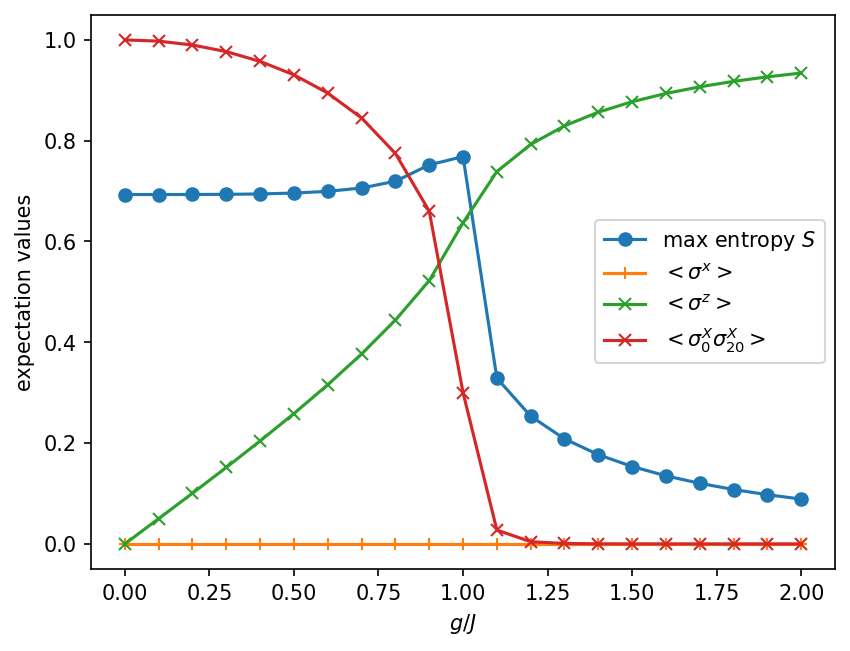

In [23]:
plt.plot(gs, entropies, marker='o', label='max entropy $S$')
# plot expecation values of sigmax and sigmaz as well
plt.plot(gs, vals_X, marker='+', label=r'$<\sigma^x>$')
plt.plot(gs, vals_Z, marker='x', label=r'$<\sigma^z>$')
plt.plot(gs, corrs_XX, marker='x', label=r'$<\sigma^X_0 \sigma^X_{20}>$')


plt.xlabel('$g/J$')
plt.ylabel('expectation values')
plt.legend(loc='best')


# Simulations

For large-scale simulations, especially when running on a computing cluster, we recommend looking into the tenpy Simulation setup.

For that, read the [user guide on Simulations](https://tenpy.readthedocs.io/en/latest/intro/simulations.html).

You can explore the setup in a jupyter notebook as illustrated in the following cell.
Note that you should install the packages `pyyaml` and `h5py` for this:
```bash
pip install pyyaml h5py
# or
conda install pyyaml h5py
```




In [24]:
import yaml

In [25]:
simulation_params = tenpy.load_yaml_with_py_eval(yaml_content="""
simulation_class : GroundStateSearch
output_filename: DMRG_sim_example.pkl

model_class:  TFIModel
model_params:
    L : 32
    bc_MPS : finite

initial_state_params:
    method : lat_product_state
    product_state : [[up]]

algorithm_class: TwoSiteDMRGEngine
algorithm_params:
    trunc_params:
        chi_max: 100
""")
pprint(simulation_params)

{'algorithm_class': 'TwoSiteDMRGEngine',
 'algorithm_params': {'trunc_params': {'chi_max': 100}},
 'initial_state_params': {'method': 'lat_product_state',
                          'product_state': [['up']]},
 'model_class': 'TFIModel',
 'model_params': {'L': 32, 'bc_MPS': 'finite'},
 'output_filename': 'DMRG_sim_example.pkl',
 'simulation_class': 'GroundStateSearch'}


In [26]:
tenpy.run_simulation(**simulation_params)

  warnings.warn(f"changed output filename to {new_out_fn!s}")

INFO    : new simulation
GroundStateSearch
INFO    : output filename: DMRG_sim_example_1.pkl
INFO    : use trivial cache (keeps everything in RAM)
INFO    : GroundStateSearch: reading 'algorithm_params'={'trunc_params': {'chi_max': 100}}
INFO    : No cache due to chi=100 < cache_threshold_chi = 2000
INFO    : use trivial cache (keeps everything in RAM)
INFO    : GroundStateSearch: reading 'model_class'='TFIModel'
INFO    : GroundStateSearch: subconfig 'model_params'=Config(<2 options>, 'model_params')
INFO    : model_params: reading 'bc_MPS'='finite'
INFO    : model_params: reading 'L'=32
INFO    : GroundStateSearch: subconfig 'initial_state_params'=Config(<2 options>, 'initial_state_params')
INFO    : initial_state_params: reading 'method'='lat_product_state'
INFO    : calling InitialStateBuilder.lat_product_state()
INFO    : initial_state_params: reading 'product_state'=[['up']]
INFO    : GroundStateSearch: reading 'algor

{'simulation_parameters': {'output_filename': 'DMRG_sim_example.pkl',
  'model_class': 'TFIModel',
  'model_params': {'L': 32,
   'bc_MPS': 'finite',
   'explicit_plus_hc': False,
   'lattice': 'Chain',
   'order': 'default',
   'conserve': 'parity',
   'sort_charge': True,
   'bc_x': 'open',
   'helical_lattice': None,
   'irregular_remove': None,
   'J': 1.0,
   'g': 1.0,
   'sort_mpo_legs': False},
  'initial_state_params': {'method': 'lat_product_state',
   'product_state': [['up']],
   'check_filling': None,
   'dtype': None,
   'allow_incommensurate': False,
   'check_global_charge': None},
  'algorithm_class': 'TwoSiteDMRGEngine',
  'algorithm_params': {'trunc_params': {'chi_max': 100,
    'chi_min': None,
    'degeneracy_tol': None,
    'svd_min': 1e-14,
    'trunc_cut': 1e-14},
   'diag_method': 'default',
   'max_N_sites_per_ring': 18,
   'combine': False,
   'lanczos_params': {'N_min': 2,
    'N_max': 20,
    'P_tol': np.float64(7.259751087216598e-29),
    'min_gap': 1e-12,
